# Data Pre-Processing | CE-04

## Dataset :Periodic Labour Force Survey (PLFS) 2022 person-level data
## Source : MoSPI (https://microdata.gov.in/nada/index.php/catalog/211/get-microdata)

## Title : Data Preprocessing and Linear Regression Analysis of Education and Earnings in Karnataka Using PLFS 2022 Data
## Objective : To estimate how a worker's earnings change with each additional year of education and how well education alone explains differences in earnings.

## Description : 
- About 12,800 first-stage units (7,024 villages and 5,776 urban blocks) are covered each year at the all-India level. The survey uses a stratified, multi-stage design. In urban areas, households are visited four times under a rotational panel scheme, while rural samples are spread across quarters.

## Importing the libraries

In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error

In [82]:
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy.stats import shapiro

## 1. Loading the dataset

In [3]:
data = pd.read_csv(r"C:\Users\nikit.LAPTOP-099SQUHM\Downloads\cperv1.csv")
data.head()

,panel_cperv1,FI_cperv1,B1q2_cperv1,qtr_cperv1,visit_cperv1,b1q3_cperv1,state_cperv1,distcode_cperv1,nss_region_cperv1,b1q5_cperv1,...,b6q8_act2_3pt7_cperv1,b6q5_cperv1,b6q6_cperv1,b6q7_cperv1,b6q9_cperv1,b6q10_cperv1,nss_cperv1,nsc_cperv1,mult_cperv1,no_qtr_cperv1
0,P3,CFVP2,104,Q3,V1,1,28,2,281,1,...,0,11,1.0,611.0,0,12000,1,2,1293611.0,4
1,P3,CFVP2,104,Q3,V1,1,28,2,281,1,...,0,31,84.0,335.0,5000,0,1,2,1293611.0,4
2,P3,CFVP2,104,Q3,V1,1,28,2,281,1,...,0,21,1.0,611.0,0,0,1,2,1293611.0,4
3,P3,CFVP2,104,Q3,V1,1,28,2,281,1,...,0,31,84.0,335.0,12000,0,1,2,1293611.0,4
4,P3,CFVP2,104,Q3,V1,1,28,2,281,1,...,0,11,1.0,611.0,0,15000,1,2,1293611.0,4


In [4]:
data.shape

(424926, 140)

In [5]:
data.dtypes

panel_cperv1      object
FI_cperv1         object
B1q2_cperv1        int64
qtr_cperv1        object
visit_cperv1      object
                  ...   
b6q10_cperv1       int64
nss_cperv1         int64
nsc_cperv1         int64
mult_cperv1      float64
no_qtr_cperv1      int64
Length: 140, dtype: object

Interpretation : The dataset from MoSPI consists of 4,24,926 rows and 140 columns(features), we have integer, object and float as our data types

In [6]:
data["state_cperv1"] = data["state_cperv1"].astype(str).str.strip() 

In [7]:
cols_to_keep = [
    "b4q5_cperv1", "b4q6_perv1", "b4q7_cperv1", "b1q3_cperv1",
    "distcode_cperv1", "qtr_cperv1", "b4q10_cperv1", "b4q8_cperv1",
    "b4q12_cperv1", "b6q5_cperv1", "b5pt1q10_cperv1", "b5pt1q11_cperv1",
    "b6q9_cperv1",
]
# keeping only Karnataka rows and only these columns, as a separate dataframe
df = data.loc[data["state_cperv1"] == "29", cols_to_keep].copy()

print(df.shape)

(15791, 13)


In [8]:
rename_map = {
    "b4q5_cperv1": "sex", "b4q6_perv1": "age", "b4q7_cperv1": "marital_status",
    "b1q3_cperv1": "sector", "distcode_cperv1": "district", "qtr_cperv1": "quarter",
    "b4q10_cperv1": "edu_years", "b4q8_cperv1": "edu_level", "b4q12_cperv1": "training",
    "b6q5_cperv1": "weekly_status", "b5pt1q10_cperv1": "enterprise_size",
    "b5pt1q11_cperv1": "job_contract", "b6q9_cperv1": "earnings"}
df = df.rename(columns=rename_map)

raw = df.copy()     # the raw data which isn't pre-processed
clean = df.copy()   # the dataframe that we will work on

In [9]:
df["district"].nunique() #30 districts in karnataka

30

In [10]:
df.to_csv("processed/karnataka_raw_subset.csv", index=False)

print("saved")

saved


Interpretation : choosing the features to keep and chose the state karnataka as a subset to work with, stored the subset as a separate csv file for future references.

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15791 entries, 38854 to 362567
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   sex              15791 non-null  int64  
 1   age              15791 non-null  int64  
 2   marital_status   15791 non-null  int64  
 3   sector           15791 non-null  int64  
 4   district         15791 non-null  int64  
 5   quarter          15791 non-null  object 
 6   edu_years        15791 non-null  int64  
 7   edu_level        15791 non-null  int64  
 8   training         11459 non-null  float64
 9   weekly_status    15791 non-null  int64  
 10  enterprise_size  6433 non-null   float64
 11  job_contract     3594 non-null   float64
 12  earnings         15791 non-null  int64  
dtypes: float64(3), int64(9), object(1)
memory usage: 1.7+ MB


In [12]:
df.head()

,sex,age,marital_status,sector,district,quarter,edu_years,edu_level,training,weekly_status,enterprise_size,job_contract,earnings
38854,1,46,2,1,21,Q3,7,7,6.0,11,1.0,NaN,0
38855,1,22,1,1,21,Q3,14,11,6.0,91,NaN,NaN,0
38856,1,20,1,1,21,Q3,10,8,6.0,51,1.0,1.0,0
38857,2,42,2,1,21,Q3,5,6,6.0,11,1.0,NaN,0
38858,2,16,1,1,21,Q3,11,8,6.0,91,NaN,NaN,0


Interpretation : The data preview shows the kind of data is present in each columns and in weekly status we have codes that are to be referenced to the data dictionary from the source, district is in code aswell, changing datatype to category for required columns will help us understand the data better.

In [13]:
raw.shape

(15791, 13)

In [14]:
clean['earnings'].describe()

count     15791.000000
mean       2844.959154
std        9541.293190
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max      120000.000000
Name: earnings, dtype: float64

Interpretation : The maximum earnings is 1,20,000 rupees but the quartiles are all 0, indicating the 0 here must indicate not answered or not earning.

In [15]:
clean['earnings'].unique()

array([     0,   9000,   5500,  10000,  13000,   5000,  12500,   7000,
         6000,  11000,   8000,  16000,  14000,  22000,  18000,  25000,
        28000,  15000,  12000,  32000,  16200,  13500,  40000,   3000,
        35000,  20000,   3700,  34000,   8300,  25400,  12800,   7500,
         6500,  58000,  41000,   4000,  10500,  12700,  63400,  38000,
        30000,  48000,  42000,  50000,  34500,  33600,  65000,  37500,
        17500,  27000,   2500,  21000,  16500,   4500,  45000,  41700,
        26400,  24000,  28500,  38500,  18500, 115000,  51000,  60000,
        10600,  78000,  23500,  11500,  11800,   8500,  43000, 105000,
        55000,  29000,  80000,  17000,  70000,  14500,  36000,   2000,
        26000,  19000,  15500,  64000,  44000,  56400,  23000,  73000,
        37600,  33000,   9500,   9200,  57000,  55500,  82500,  50500,
        28400,  25500, 120000,  52000,  75000,  47000,  54000,  61000,
        18400,  21600,  48300,  14800,   5200,   3500,  13200,  14200,
      

In [16]:
zero_count = (clean['earnings'] == 0).sum()
total_count = len(clean)

percentage = (zero_count / total_count) * 100

print("Zero count:", zero_count)
print("Percentage of zeros:", percentage,"%")

Zero count: 13768
Percentage of zeros: 87.18890507250966 %


In [17]:
clean[(clean['earnings'] == 0) & (clean['weekly_status'] == 31)].sum()

sex                  0
age                  0
marital_status       0
sector               0
district             0
quarter              0
edu_years            0
edu_level            0
training           0.0
weekly_status        0
enterprise_size    0.0
job_contract       0.0
earnings             0
dtype: object

Interpretation : The code 31 stands for : Worked as a regular salaried or wage employee, upon checking if anyone that has worked has an actual earning of 0, we can confirm that 0 here indicates those people were never asked for their earnings.


In [18]:
clean['earnings'] = clean['earnings'].replace(0, np.nan)

In [19]:
clean['earnings'].isna().sum()

np.int64(13768)

Interpretaion : All the rows where the salary was marked as 0 has been turned into NaN for appropriate data analysis.

In [20]:
clean['earnings'].describe()

count      2023.000000
mean      22206.994563
std       16754.883156
min        1000.000000
25%       10000.000000
50%       15000.000000
75%       30000.000000
max      120000.000000
Name: earnings, dtype: float64

Interpretation : The mean earning is 22,207 rupees and median earning is 15,000 rupees.

In [21]:
clean['weekly_status'].unique()

# The codes 42, 51 have weekly earnings recorded whereas all the other codes have monthly earnings recorded

array([11, 91, 51, 94, 92, 99, 95, 12, 31, 98, 62, 21, 81, 93, 97, 42, 82,
       61, 72, 71])

In [22]:
weekly = clean[(clean['weekly_status'] == 42) | 
            (clean['weekly_status'] == 51)]

In [23]:
weekly['earnings'].describe()

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: earnings, dtype: float64

In [24]:
monthly = clean[(clean['weekly_status'] != 42) & 
             (clean['weekly_status'] != 51)]

In [25]:
monthly['earnings'].describe()

count      2023.000000
mean      22206.994563
std       16754.883156
min        1000.000000
25%       10000.000000
50%       15000.000000
75%       30000.000000
max      120000.000000
Name: earnings, dtype: float64

Interpretation : The weekly earnings were all 0, Indication they were never asked so the earlier interpretation of the statistical summary holds true and the count of valid earnings is 2023.

In [26]:
#Block 2 

clean.isna().sum()

sex                    0
age                    0
marital_status         0
sector                 0
district               0
quarter                0
edu_years              0
edu_level              0
training            4332
weekly_status          0
enterprise_size     9358
job_contract       12197
earnings           13768
dtype: int64

In [27]:
(clean.isna().sum() / len(clean)) * 100

sex                 0.000000
age                 0.000000
marital_status      0.000000
sector              0.000000
district            0.000000
quarter             0.000000
edu_years           0.000000
edu_level           0.000000
training           27.433348
weekly_status       0.000000
enterprise_size    59.261605
job_contract       77.240200
earnings           87.188905
dtype: float64

Interpretation : The amount od missing values in training is 27%, enterprise size is 59%, job contract is 77%.

In [28]:
clean_age = clean[(clean['age'] >= 12) & (clean['age'] <= 59)]

print("People aged 12 to 59:", len(clean_age))

People aged 12 to 59: 11459


In [29]:
print("Training true gaps:", clean_age['training'].isna().sum())

Training true gaps: 0


In [30]:
print("Training structural blanks:", clean['training'].isna().sum() - clean_age['training'].isna().sum())

Training structural blanks: 4332


In [31]:
clean_work = clean[clean['earnings'].notna()]

print("People with valid earnings:", len(clean_work))

People with valid earnings: 2023


In [32]:
print("Enterprise size true gaps:", clean_work['enterprise_size'].isna().sum())

Enterprise size true gaps: 5


In [33]:
print("Enterprise size structural blanks:", clean['enterprise_size'].isna().sum() - clean_work['enterprise_size'].isna().sum())

Enterprise size structural blanks: 9353


In [34]:
print("Job contract true gaps:", clean_work['job_contract'].isna().sum())

Job contract true gaps: 7


In [35]:
print("Job contract structural blanks:", clean['job_contract'].isna().sum() - clean_work['job_contract'].isna().sum())

Job contract structural blanks: 12190


In [36]:
true_gaps = clean_age['training'].isna().sum()
eligible = len(clean_age)

print("True gap percentage:", (true_gaps / eligible) * 100)

True gap percentage: 0.0


In [37]:
true_gaps = clean_work['enterprise_size'].isna().sum()
eligible = len(clean_work)

print("True gap percentage:", (true_gaps / eligible) * 100)

True gap percentage: 0.2471576866040534


In [38]:
true_gaps = clean_work['job_contract'].isna().sum()
eligible = len(clean_work)

print("True gap percentage:", (true_gaps / eligible) * 100)

True gap percentage: 0.34602076124567477


In [39]:
#handling the blank values

clean_work['enterprise_size'].mode()

0    4.0
Name: enterprise_size, dtype: float64

In [40]:
mode_enterprise = clean_work['enterprise_size'].mode()[0]

clean.loc[(clean['earnings'].notna()) & (clean['enterprise_size'].isna()),'enterprise_size'] = mode_enterprise

In [41]:
clean_work['job_contract'].mode()

0    1.0
Name: job_contract, dtype: float64

In [42]:
mode_contract = clean_work['job_contract'].mode()[0]

clean.loc[(clean['earnings'].notna()) & (clean['job_contract'].isna()),'job_contract'] = mode_contract

In [43]:
print("Training blanks after:", clean['training'].isna().sum())

print("Enterprise size blanks after:", clean['enterprise_size'].isna().sum())

print("Job contract blanks after:", clean['job_contract'].isna().sum())

Training blanks after: 4332
Enterprise size blanks after: 9353
Job contract blanks after: 12190


Interpretation : The missing values in the training, enterprise size, and job contract columns were classified into structural blanks and true gaps. For training, age between 12 and 59 was used as the eligibility criterion, for enterprise size and job contract, the presence of valid earnings was used.
No true gaps were identified in training, while enterprise size and job contract contained 5 and 7 true gaps, respectively. Structural blanks were left as blanks itself cause imputing those values would mean we are inventing new data that did not exist earlier, the true gaps in the two work-related columns were imputed using the mode, as these are categorical variables.

In [44]:
# Block 3

clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15791 entries, 38854 to 362567
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   sex              15791 non-null  int64  
 1   age              15791 non-null  int64  
 2   marital_status   15791 non-null  int64  
 3   sector           15791 non-null  int64  
 4   district         15791 non-null  int64  
 5   quarter          15791 non-null  object 
 6   edu_years        15791 non-null  int64  
 7   edu_level        15791 non-null  int64  
 8   training         11459 non-null  float64
 9   weekly_status    15791 non-null  int64  
 10  enterprise_size  6438 non-null   float64
 11  job_contract     3601 non-null   float64
 12  earnings         2023 non-null   float64
dtypes: float64(4), int64(8), object(1)
memory usage: 1.7+ MB


In [45]:
code_columns = ['sex','marital_status','sector','district','quarter','edu_level','training','weekly_status','enterprise_size','job_contract']

for col in code_columns:
    clean[col] = clean[col].astype("category")

In [46]:
clean.dtypes

sex                category
age                   int64
marital_status     category
sector             category
district           category
quarter            category
edu_years             int64
edu_level          category
training           category
weekly_status      category
enterprise_size    category
job_contract       category
earnings            float64
dtype: object

Interpretation : The .info() method was used to examine the original data types. The dataset contained numerical columns, categorical codes, and a quarter column stored as an object. Although several columns were stored as integers or floats, their values represented categories rather than measurable quantities.

- The columns sex, marital_status, sector, district, quarter, edu_level, training, weekly_status, enterprise_size, and job_contract were converted to the category data type using .astype("category"). The columns age, edu_years, and earnings were retained as numerical variables.

- It helps prevent categorical codes from being mistakenly interpreted as meaningful numerical quantities.

In [47]:
# block 4

clean.duplicated().sum() 

np.int64(1417)

In [48]:
print(data[["b1q13_cperv1", "b1q14_cperv1"]].head())

   b1q13_cperv1  b1q14_cperv1
0             1             1
1             1             1
2             1             1
3             1             1
4             1             1


In [49]:
id_cols = ["b1q1_cperv1", "b1q15_cperv1", "b4q1_cperv1"]

ids = data.loc[clean.index, id_cols]

In [50]:
id_cols = ["b1q13_cperv1", "b1q14_cperv1"]

ids = data.loc[clean.index, id_cols]
duplicate_check = clean.join(ids)

print("Duplicate rows:", duplicate_check.duplicated().sum())

Duplicate rows: 414


In [51]:
duplicate_check[duplicate_check.duplicated(keep=False)].sort_values(id_cols)

,sex,age,marital_status,sector,district,quarter,edu_years,edu_level,training,weekly_status,enterprise_size,job_contract,earnings,b1q13_cperv1,b1q14_cperv1
39028,1,4,1,1,16,Q3,0,1,NaN,99,NaN,NaN,NaN,1,1
39115,1,4,1,1,16,Q3,0,1,NaN,99,NaN,NaN,NaN,1,1
39722,2,10,1,1,4,Q3,4,5,NaN,91,NaN,NaN,NaN,1,1
39793,2,1,1,1,26,Q3,0,1,NaN,99,NaN,NaN,NaN,1,1
39803,2,1,1,1,26,Q3,0,1,NaN,99,NaN,NaN,NaN,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
360130,1,19,1,2,2,Q5,13,10,6.0,91,NaN,NaN,NaN,2,3
360131,1,19,1,2,2,Q5,13,10,6.0,91,NaN,NaN,NaN,2,3
360571,1,20,1,2,15,Q6,14,10,6.0,91,NaN,NaN,NaN,2,3
360572,1,20,1,2,15,Q6,14,10,6.0,91,NaN,NaN,NaN,2,3


Interpretation : Duplicate records were checked using the 13 selected variables and three identifier columns recovered from the original dataset. The check identified 0 duplicate row occurrences.

In [52]:
# block 5

print(clean["weekly_status"].value_counts(dropna=False).sort_index())

weekly_status
11    1871
12     160
21     714
31    2011
42       3
51    1477
61       3
62      84
71       1
72      13
81     249
82      34
91    3678
92    2968
93     248
94     971
95     173
97     137
98      11
99     985
Name: count, dtype: int64


In [53]:
model = clean.copy()

print("Starting rows:", len(model))

# Filter 1: Regular wage/salaried employees (status 31)
model = model[model["weekly_status"] == 31]
print("Salaried employees:", len(model))

# Filter 2: Valid earnings
model = model[model["earnings"].notna()]
print("Valid earnings:", len(model))

# Filter 3: Valid education years
model = model[model["edu_years"].notna()]
print("Valid education years:", len(model))

Starting rows: 15791
Salaried employees: 2011
Valid earnings: 2011
Valid education years: 2011


In [54]:
print("Age summary:")
print(model["age"].describe())

print("\nWorkers younger than 18:")
print(model[model["age"] < 18][["age", "edu_years", "earnings"]])

print("\nEducation years summary:")
print(model["edu_years"].describe())

print("\nEducation years below 0:")
print(model[model["edu_years"] < 0])

print("\nEducation years above 25:")
print(model[model["edu_years"] > 25])

Age summary:
count    2011.000000
mean       35.785679
std        10.893894
min        15.000000
25%        27.000000
50%        34.000000
75%        43.000000
max        77.000000
Name: age, dtype: float64

Workers younger than 18:
        age  edu_years  earnings
146857   16          8    4500.0
147667   17         10    9000.0
149571   17          9   10000.0
150332   17          8   12500.0
358845   15         10    6000.0
360167   17         10    5000.0
360317   17          9    8000.0

Education years summary:
count    2011.000000
mean       11.616609
std         4.499939
min         0.000000
25%         9.000000
50%        12.000000
75%        15.000000
max        21.000000
Name: edu_years, dtype: float64

Education years below 0:
Empty DataFrame
Columns: [sex, age, marital_status, sector, district, quarter, edu_years, edu_level, training, weekly_status, enterprise_size, job_contract, earnings]
Index: []

Education years above 25:
Empty DataFrame
Columns: [sex, age, marital_sta

In [55]:
print(model[model["age"] < 18][
    ["age", "marital_status", "sector", "edu_level", "edu_years", "earnings"]])

        age marital_status sector edu_level  edu_years  earnings
146857   16              1      2         7          8    4500.0
147667   17              1      2         8         10    9000.0
149571   17              1      2         7          9   10000.0
150332   17              1      2         7          8   12500.0
358845   15              1      2         8         10    6000.0
360167   17              1      2         8         10    5000.0
360317   17              1      2         7          9    8000.0


In [56]:
print("Final modelling rows:", len(model))
print("Missing earnings:", model["earnings"].isna().sum())
print("Missing education years:", model["edu_years"].isna().sum())

Final modelling rows: 2011
Missing earnings: 0
Missing education years: 0


In [57]:
print(model[model["age"] < 18][
    ["age", "edu_level", "edu_years"]
])

        age edu_level  edu_years
146857   16         7          8
147667   17         8         10
149571   17         7          9
150332   17         7          8
358845   15         8         10
360167   17         8         10
360317   17         7          9


Interpretation : The final modelling subset contains 2,009 salaried workers with valid earnings and education-year values. Ages range from 15 to 77 years, with a mean of 35.78 years. Seven workers are below 18, including a 15-year-old with eight years of education earning ₹6,000. This suggests possible early entry into employment after limited schooling, although the data cannot confirm whether these individuals left school to work. These observations were retained as their values were not sufficient to establish errors.

In [58]:
# block 6

print("Mean earnings:", model["earnings"].mean())
print("Median earnings:", model["earnings"].median())
print("Skewness before log:", model["earnings"].skew())

Mean earnings: 22242.889109895576
Median earnings: 15000.0
Skewness before log: 1.5592516626941828


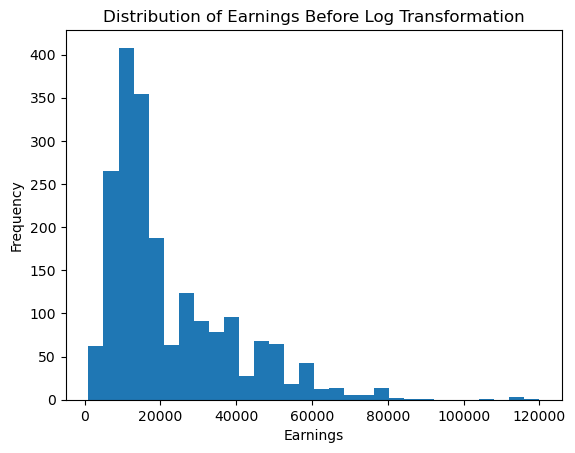

In [59]:
plt.hist(model["earnings"], bins=30)
plt.xlabel("Earnings")
plt.ylabel("Frequency")
plt.title("Distribution of Earnings Before Log Transformation")
plt.show()

In [60]:
model["log_earnings"] = np.log(model["earnings"])

In [61]:
print("Skewness after log:", model["log_earnings"].skew())

Skewness after log: -0.04024858111364891


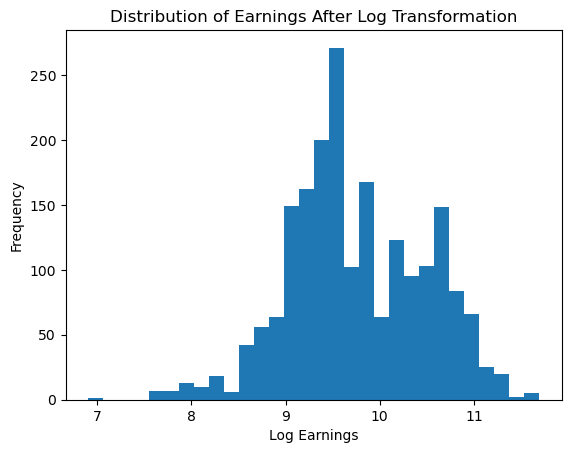

In [62]:
plt.hist(model["log_earnings"], bins=30)
plt.xlabel("Log Earnings")
plt.ylabel("Frequency")
plt.title("Distribution of Earnings After Log Transformation")
plt.show()

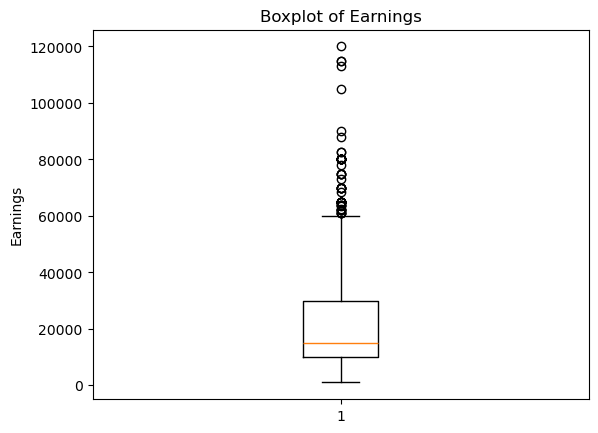

In [63]:
plt.boxplot(model["earnings"])
plt.ylabel("Earnings")
plt.title("Boxplot of Earnings")
plt.show()

In [64]:
Q1 = model["earnings"].quantile(0.25)
Q3 = model["earnings"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = model[
    (model["earnings"] < lower) |
    (model["earnings"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower fence:", lower)
print("Upper fence:", upper)
print("Number of outliers:", len(outliers))

Q1: 10000.0
Q3: 30000.0
IQR: 20000.0
Lower fence: -20000.0
Upper fence: 60000.0
Number of outliers: 61


Interpretation : The mean earnings were 22,000 rs, compared with a median of 15,000 rs. The original earnings distribution had a skewness of 1.56, which changed to -0.04 after log transformation. The histograms were compared to assess whether the transformation improved symmetry. The IQR method identified 61 potential outliers. These observations were retained because extreme earnings values are not necessarily errors.

# Regression

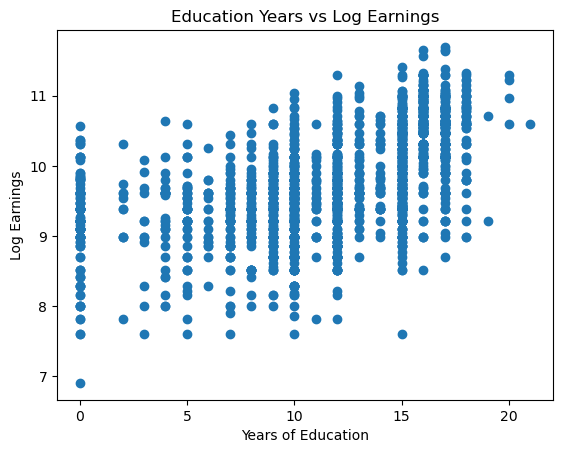

In [65]:
#Scatter plot 

plt.scatter(model["edu_years"], model["log_earnings"])
plt.xlabel("Years of Education")
plt.ylabel("Log Earnings")
plt.title("Education Years vs Log Earnings")
plt.show()

Interpretation : We can observe that the years 10, 12 and 15 are clustered whereas the other education years are sparsely distributed.

In [67]:
Correlation = model["edu_years"].corr(model["log_earnings"])

In [68]:
Correlation

np.float64(0.561501169812235)

Interpretation : The correlation between years of education and log earnings was 0.562, indicating a moderate positive relationship. Workers with more years of education generally tend to have higher log earnings. 

In [69]:
grouped = model.groupby("edu_years")["log_earnings"].mean()

In [70]:
grouped

edu_years
0      9.187206
2      9.309028
3      9.043282
4      9.231173
5      9.245244
6      9.271049
7      9.237221
8      9.343313
9      9.380402
10     9.396140
11     9.508057
12     9.546364
13     9.869411
14     9.860127
15     9.980193
16    10.584421
17    10.418613
18    10.500909
19     9.962379
20    11.019965
21    10.596635
Name: log_earnings, dtype: float64

Interpretation : Average log earnings generally increase with years of education, consistent with the positive correlation of 0.562. However, some fluctuations occur at higher education levels, particularly from 17 to 21 years.

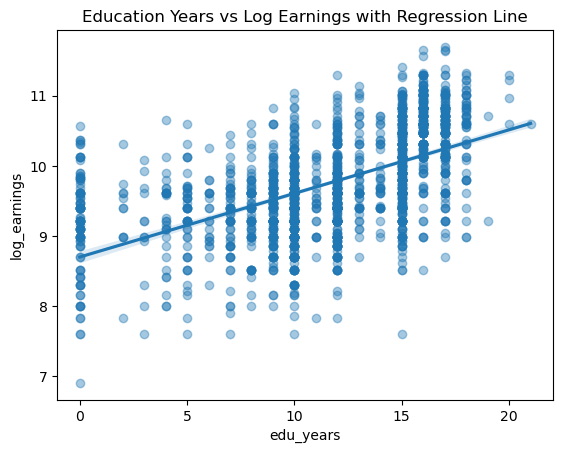

In [72]:
sns.regplot(
    data=model,
    x="edu_years",
    y="log_earnings",
    scatter_kws={"alpha": 0.4})
plt.title("Education Years vs Log Earnings with Regression Line")
plt.show()

Interpretation : The scatter plot shows a moderate positive relationship between years of education and log earnings, supported by a correlation coefficient of 0.562. The upward-sloping regression line suggests that earnings generally increase with education. However, the spread of points indicates that other factors also influence earnings, and the relationship is not perfectly linear.

In [75]:
# Before part

before = raw[["edu_years", "earnings"]].dropna()

X = sm.add_constant(before["edu_years"])
y = before["earnings"]

model_before = sm.OLS(y, X).fit()

predictions = model_before.predict(X)
rmse = np.sqrt(mean_squared_error(y, predictions))

print("Slope:", model_before.params["edu_years"])
print("R-squared:", model_before.rsquared)
print("RMSE:", rmse)
print("Number of rows:", len(before))

print(model_before.summary())

Slope: 626.7029960351272
R-squared: 0.12365917583069264
RMSE: 8931.615348396313
Number of rows: 15791
                            OLS Regression Results                            
Dep. Variable:               earnings   R-squared:                       0.124
Model:                            OLS   Adj. R-squared:                  0.124
Method:                 Least Squares   F-statistic:                     2228.
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        06:15:37   Log-Likelihood:            -1.6606e+05
No. Observations:               15791   AIC:                         3.321e+05
Df Residuals:                   15789   BIC:                         3.321e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------

Interpretation : The baseline regression uses 15,791 observations, including zero earnings. The slope of 626.70 indicates that each additional year of education is associated with an average increase of approximately ₹627 in earnings. The R² value of 0.124 indicates that education explains only 12.4% of the variation in earnings, suggesting a weak model fit. The RMSE is ₹8,931.62, indicating substantial prediction errors. This model serves as a baseline for comparison with the model fitted after data processing.

In [78]:
# train test split

X = model[["edu_years"]]
y = model["log_earnings"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

X_train_const = sm.add_constant(X_train)
X_test_const = sm.add_constant(X_test)

model_after = sm.OLS(y_train, X_train_const).fit()

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Intercept:", model_after.params["const"])
print("Slope:", model_after.params["edu_years"])
print("R-squared:", model_after.rsquared)

print(model_after.summary())

Training rows: 1407
Testing rows: 604
Intercept: 8.72569175309415
Slope: 0.08898377375991358
R-squared: 0.3080242736004296
                            OLS Regression Results                            
Dep. Variable:           log_earnings   R-squared:                       0.308
Model:                            OLS   Adj. R-squared:                  0.308
Method:                 Least Squares   F-statistic:                     625.4
Date:                Thu, 29 Oct 2026   Prob (F-statistic):          1.77e-114
Time:                        06:21:48   Log-Likelihood:                -1290.9
No. Observations:                1407   AIC:                             2586.
Df Residuals:                    1405   BIC:                             2596.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------

Interpretation : The dataset was split into 1,407 training observations and 604 testing observations. The fitted regression equation is:

log(earnings) = 8.7257 + 0.0890 × edu_years

The positive slope of 0.089 indicates that each additional year of education is associated with approximately 9.3% higher earnings on average. The R² value of 0.308 indicates that education explains 30.8% of the variation in log earnings in the training data. This suggests a moderate relationship between education and earnings.

**Interpretation**:
- **Slope t-statistic:** 25.008. This indicates strong evidence that the education coefficient differs from zero.
- **Slope p-value:** Approximately 0.000 (p < 0.05). The relationship between education and log earnings is statistically significant at the 5% level.
- **95% confidence interval:** [0.082, 0.096]. The estimated slope is likely to lie within this interval at the 95% confidence level.
- **F-statistic:** 625.4. This indicates that the regression model is statistically significant overall.
- **F-test p-value:** 1.77 × 10⁻¹¹⁴. This is far below 0.05, confirming that the model is statistically significant.
- **R²:** 0.308. Education explains 30.8% of the variation in log earnings in the training data.
- **Adjusted R²:** 0.308. It is almost identical to R² because the model contains only one predictor.

**Conclusion:** Education has a statistically significant positive relationship with log earnings. The slope's t-test and the overall F-test agree because this is a simple linear regression with one predictor. However, statistical significance does not imply that education explains all differences in earnings or that the relationship is causal.

In [81]:
# Predict log earnings on test data
y_pred = model_after.predict(X_test_const)

# Calculate performance metrics
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)

print("Training R-squared:", model_after.rsquared)
print("Testing R-squared:", test_r2)
print("Test RMSE:", rmse)
print("Test MAE:", mae)

# Convert predictions back to earnings
predicted_earnings = np.exp(y_pred)
print("\nFirst 5 predicted earnings:")
print(predicted_earnings.head())

Training R-squared: 0.3080242736004296
Testing R-squared: 0.3317414787710915
Test RMSE: 0.5906192765719287
Test MAE: 0.48381147449667417

First 5 predicted earnings:
359116    25576.573996
147714    23398.995182
147229    25576.573996
359363    23398.995182
147382     8792.258067
dtype: float64


Interpretation : The model was evaluated on 604 observations in the test set. The test R² was 0.332, compared with the training R² of 0.308. Since the test R² is slightly higher than the training R², there is no clear indication of overfitting. The test RMSE was 0.591 and the test MAE was 0.484, both measured in log units. The model explains approximately 33.2% of the variation in log earnings on unseen data, indicating moderate predictive performance.

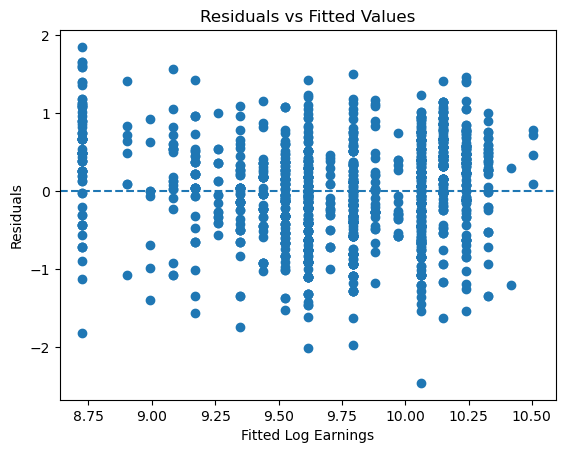

In [88]:
#testing the assumption

residuals = model_after.resid
fitted = model_after.fittedvalues

# 1. Residuals vs fitted plot
plt.scatter(fitted, residuals)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Fitted Log Earnings")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values")
plt.show()

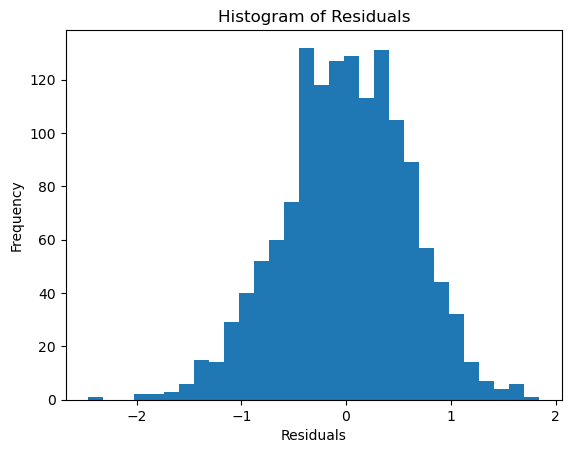

In [84]:
# 2. Histogram of residuals
plt.hist(residuals, bins=30)
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Histogram of Residuals")
plt.show()

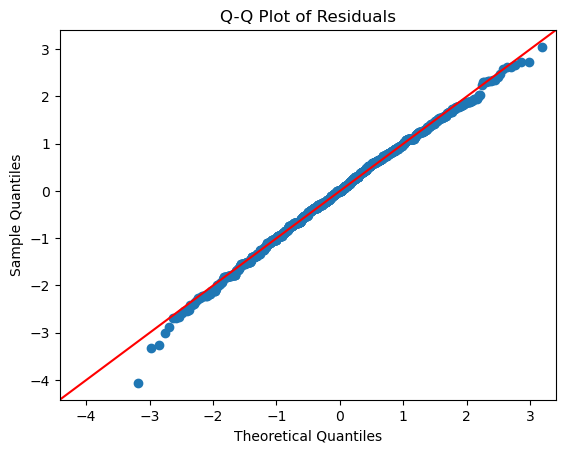

In [85]:
# 3. Q-Q plot
sm.qqplot(residuals, line="45", fit=True)
plt.title("Q-Q Plot of Residuals")
plt.show()

In [86]:
# 4. Breusch-Pagan test
bp_test = het_breuschpagan(residuals, model_after.model.exog)
print("Breusch-Pagan p-value:", bp_test[1])

Breusch-Pagan p-value: 0.0006650876994755701


In [87]:
# 5. Normality test
shapiro_stat, shapiro_p = shapiro(residuals.sample(min(5000, len(residuals)), random_state=42))
print("Shapiro-Wilk p-value:", shapiro_p)

Shapiro-Wilk p-value: 0.029212604355974392


**Interpretation** : 
- **Linearity:** The residuals are generally scattered around zero without a strong curved pattern, suggesting that the linearity assumption is reasonably satisfied.
- **Constant variance:** The Breusch-Pagan test gives a p-value below 0.05, indicating non-constant residual variance (heteroscedasticity).
- **Normality:** The histogram is approximately bell-shaped and the Q-Q plot follows the diagonal fairly closely, although some deviations occur at the tails. However, the Shapiro-Wilk test gives a p-value below 0.05, suggesting a statistically significant departure from normality. Therefore, the normality assumption is not fully satisfied.
- **Overall:** The model satisfies linearity reasonably well, but heteroscedasticity and slight departures from normality suggest that some regression assumptions may not hold fully. The vertical stripes in the residual plot are expected because education years are whole-number values.

In [90]:
#comparison

comparison = pd.DataFrame({
    "Model": ["Raw Model", "Final Model"],
    "Rows Used": [15791, len(model)],
    "Target": ["Earnings", "Log Earnings"],
    "Slope": [626.703, model_after.params["edu_years"]],
    "R-squared": [0.124, test_r2],
    "RMSE": [8931.615, rmse]})

In [91]:
comparison

,Model,Rows Used,Target,Slope,R-squared,RMSE
0,Raw Model,15791,Earnings,626.703000,0.124000,8931.615000
1,Final Model,2011,Log Earnings,0.088984,0.331741,0.590619


Comparison:

The raw model used 15,791 observations and had an R² of 0.124, indicating that education explained 12.4% of the variation in earnings. The final model used log earnings for salaried workers and achieved a test R² of 0.332, explaining approximately 33.2% of the variation in log earnings in unseen data. Its slope of 0.089 suggests that each additional year of education is associated with approximately 9% higher earnings on average.

However, the results have limitations. Survey weights were not used, so the findings should not be generalised to the entire population. The data documentation states that the dataset is intended for employment indicators. Earnings analysis is restricted to salaried workers, creating potential selection bias. Finally, the results show an association between education and earnings, not proof that additional education causes higher pay.